# Estrutura curricular do TADS em três bancos de dados

**Disciplina:** Fundamentos e Técnicas em Ciência de Dados — Etapa 2 (em equipe)

## Objetivo

Guardar a estrutura curricular do curso de **Tecnologia em Análise e Desenvolvimento de Sistemas (TADS/UFRN, 2019)** em **três tipos de banco de dados** e comparar como cada um responde às mesmas perguntas, tanto na **forma de escrever a consulta** quanto no **tempo de resposta**.

## O problema

O curso tem 37 componentes curriculares (disciplinas, optativas e atividades complementares). Muitos têm **pré-requisitos**: para cursar *Programação Orientada a Objetos* é preciso ter feito antes *Algoritmos e Programação*. Alguns pré-requisitos têm alternativas, como *Arquitetura de Software*, que exige *Banco de Dados* **ou** *Programação Visual*. Essa regra **E/OU** vem do fluxograma do SIGAA (seta contínua = E, tracejada = OU) e está guardada nos três bancos.

## Os três bancos

| Banco | Tipo | Como guarda o curso |
|---|---|---|
| **PostgreSQL** | Relacional | Três tabelas ligadas entre si: `curso`, `componente` e `prerequisito` |
| **MongoDB** | Documentos | Um documento por componente, com os pré-requisitos dentro dele |
| **Neo4j** | Grafo | Cada componente é um nó e cada pré-requisito é uma seta (`REQUER`) |

## O que este notebook faz

1. **Carrega** os dados nos três bancos.
2. **Mostra** o mesmo componente guardado nos três modelos.
3. **Executa** a mesma pergunta nos três e **confere que as respostas são idênticas**.
4. **Mede** o tempo de cada banco em 8 tipos de consulta, com tabela e gráfico.
5. **Interpreta** os resultados.

Ele usa o mesmo código do sistema web (pasta `app/`), então o que se vê aqui é exatamente o que o site executa.

**Antes de rodar:** suba os bancos com `docker compose up -d` na raiz do projeto. Os três rodam no próprio computador (localhost), porque comparar um banco local com outro na nuvem tornaria o tempo incomparável.

## Preparação

Importa as bibliotecas e o código do sistema (`app/backends`), que contém a consulta de cada banco. `CURSO` é o código do curso que será consultado.

In [1]:
import os, sys, json, time
from statistics import mean

import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath(".."))      # raiz do projeto
from app.backends import BACKENDS
from app.backends.base import limpar, ordenar, validar

CURSO = "TADS-2019"
BANCOS = ["postgres", "mongo", "neo4j"]
NOMES = {"postgres": "PostgreSQL", "mongo": "MongoDB", "neo4j": "Neo4j"}

## 1. Carga dos dados

Os dados vêm do arquivo `data/cursos/tads-2019.json`, que foi montado a partir do fluxograma de 2019 do SIGAA. Cada componente tem código, nome, período, créditos, tipo e **pré-requisitos**.

Os pré-requisitos são uma **lista de grupos**: os grupos são ligados por **E** e os itens dentro de um grupo por **OU**.

- `[["TAD0102"], ["TAD0012"], ["TAD0103"]]` significa `TAD0102 E TAD0012 E TAD0103`
- `[["TAD0103", "TAD0111"]]` significa `TAD0103 OU TAD0111`

A célula abaixo valida o arquivo (todo pré-requisito citado precisa existir), grava o curso nos três bancos e mostra quantos componentes há em cada período. Os 2 componentes sem período são as optativas e as atividades complementares.

In [2]:
with open("../data/cursos/tads-2019.json", encoding="utf-8") as f:
    curso = json.load(f)
validar(curso)

for nome in BANCOS:
    BACKENDS[nome].carregar(curso)

componentes = pd.DataFrame(curso["componentes"])
print(f"{len(componentes)} componentes carregados nos 3 bancos")
componentes.groupby("periodo", dropna=False).size().rename("componentes").to_frame()

37 componentes carregados nos 3 bancos


,componentes
periodo,
1.0,6
2.0,7
3.0,7
4.0,7
5.0,5
6.0,3
NaN,2


Exemplo da regra E/OU nos dados de origem: *Arquitetura de Software* (um grupo com dois itens = **OU**) e *Projetos Aplicados I* (três grupos com um item cada = **E**).

In [3]:
# exemplo da regra E/OU: Arquitetura de Software exige TAD0103 OU TAD0111
[c for c in curso["componentes"] if c["codigo"] in ("TAD0029", "TAD0156")]

[{'codigo': 'TAD0029',
  'nome': 'Arquitetura de Software',
  'periodo': 4,
  'creditos': 3,
  'tipo': 'obrigatoria',
  'prerequisitos': [['TAD0103', 'TAD0111']]},
 {'codigo': 'TAD0156',
  'nome': 'Projetos Aplicados I',
  'periodo': 5,
  'creditos': 4,
  'tipo': 'obrigatoria',
  'prerequisitos': [['TAD0102'], ['TAD0012'], ['TAD0103']]}]

## 2. O mesmo dado em cada modelo

As três células a seguir mostram **o mesmo componente**, o **TAD0029 – Arquitetura de Software**, que exige `TAD0103 OU TAD0111`, como ele fica em cada banco. Repare que a informação é a mesma, só muda o formato.

- **Relacional:** o componente é uma linha na tabela `componente`, e cada pré-requisito é uma linha na tabela `prerequisito`. As duas linhas têm o mesmo `grupo` (0), o que indica **OU**. Um grupo diferente indicaria **E**.
- **Documentos:** tudo cabe em um único documento. O campo `prerequisitos` já vem na forma de lista de grupos. O `prereq_flat` é uma cópia achatada, usada só para tornar as buscas mais rápidas.
- **Grafo:** o componente é um nó e cada pré-requisito é uma seta `REQUER` apontando para outro nó, com o `grupo` guardado na própria seta.

In [4]:
pg = BACKENDS["postgres"]
print("=== Relacional: tabelas componente + prerequisito ===")
display(pd.DataFrame(pg.conn.execute(
    "SELECT * FROM componente WHERE curso = %s AND codigo = 'TAD0029'", (CURSO,)).fetchall()))
display(pd.DataFrame(pg.conn.execute(
    "SELECT * FROM prerequisito WHERE curso = %s AND componente = 'TAD0029'", (CURSO,)).fetchall()))

=== Relacional: tabelas componente + prerequisito ===


,curso,codigo,nome,nome_busca,periodo,creditos,horas,tipo
0,TADS-2019,TAD0029,Arquitetura de Software,arquitetura de software,4,3,None,obrigatoria


,curso,componente,grupo,requisito
0,TADS-2019,TAD0029,0,TAD0103
1,TADS-2019,TAD0029,0,TAD0111


In [5]:
mongo = BACKENDS["mongo"]
print("=== Documentos: um documento por componente, pré-requisitos embutidos ===")
print(json.dumps(mongo.col.find_one({"curso": CURSO, "codigo": "TAD0029"}, {"_id": 0}), indent=2, ensure_ascii=False))

=== Documentos: um documento por componente, pré-requisitos embutidos ===
{
  "curso": "TADS-2019",
  "codigo": "TAD0029",
  "nome": "Arquitetura de Software",
  "nome_busca": "arquitetura de software",
  "periodo": 4,
  "creditos": 3,
  "horas": null,
  "tipo": "obrigatoria",
  "prerequisitos": [
    [
      "TAD0103",
      "TAD0111"
    ]
  ],
  "prereq_flat": [
    "TAD0103",
    "TAD0111"
  ]
}


In [6]:
neo = BACKENDS["neo4j"]
print("=== Grafo: arestas REQUER saindo de TAD0029 ===")
pd.DataFrame(neo._run(
    "MATCH (a:Componente {curso: $c, codigo: 'TAD0029'})-[r:REQUER]->(b) "
    "RETURN a.codigo AS origem, type(r) AS relacao, r.grupo AS grupo, b.codigo AS destino, b.nome AS nome_destino",
    c=CURSO))

=== Grafo: arestas REQUER saindo de TAD0029 ===


,origem,relacao,grupo,destino,nome_destino
0,TAD0029,REQUER,0,TAD0103,Banco de Dados
1,TAD0029,REQUER,0,TAD0111,Programação Visual e Autoria Web


## 3. A mesma pergunta nos três bancos

As funções abaixo executam a consulta **na linguagem de cada banco** (SQL, pipeline do MongoDB ou Cypher) e devolvem o resultado no mesmo formato, para poder compará-los.

- `consultar(db, op, ...)` roda uma operação em um banco. O **tempo** é a média de várias execuções, depois de uma execução de **aquecimento** que não entra na conta (a primeira costuma ser mais lenta por causa de caches e conexões).
- `mostrar(op, ...)` roda nos três, imprime o número de resultados e o tempo de cada um, e **confere se os três devolveram exatamente a mesma resposta**.

As operações disponíveis são:

| Operação | Pergunta |
|---|---|
| `buscar` | Quais componentes têm tal nome, código, período, tipo ou pré-requisito? |
| `prereq_diretos` | O que um componente exige diretamente? |
| `prereq_transitivos` | Toda a cadeia: o que ele exige, o que isso exige, e assim por diante |
| `dependentes_diretos` | O que depende diretamente dele? |
| `dependentes_transitivos` | Toda a cadeia do que ele libera |

Funções auxiliares. Não precisam ser explicadas no detalhe: `filtros` prepara os parâmetros e `consultar` cronometra a consulta.

In [7]:
def filtros(nome="", codigo="", periodo=None, tipo="", requer=""):
    from app.backends.base import normalizar
    return {"nome": normalizar(nome), "codigo": codigo.upper(), "periodo": periodo,
            "tipo": tipo, "requer": requer.upper()}


def consultar(db, op, execucoes=10, **f):
    rodar, texto = BACKENDS[db].executar(op, CURSO, filtros(**f))
    rodar()                                     # aquecimento
    tempos = []
    for _ in range(execucoes):
        t0 = time.perf_counter()
        linhas = rodar()
        tempos.append((time.perf_counter() - t0) * 1000)
    return ordenar([limpar(l) for l in linhas]), mean(tempos), texto


def mostrar(op, execucoes=10, **f):
    resultados = {}
    for db in BANCOS:
        linhas, ms, texto = consultar(db, op, execucoes, **f)
        resultados[db] = (linhas, ms, texto)
        print(f"{NOMES[db]:<11} {len(linhas):>3} resultado(s)  {ms:7.2f} ms")
    iguais = all(resultados[d][0] == resultados["postgres"][0] for d in BANCOS)
    print("Resultados idênticos nos 3 bancos:", iguais)
    return resultados

### 3.1 Cadeia completa de pré-requisitos de *Projetos Aplicados II* (TAD0157)

*Projetos Aplicados II* exige *Projetos Aplicados I* e *Planejamento e Gerência de Projetos*, e cada um deles exige outros. A consulta de **cadeia** segue essas ligações até o fim.

A saída mostra, para cada banco, o número de resultados e o tempo, e depois `Resultados idênticos nos 3 bancos: True`. A tabela lista os 6 componentes que formam a cadeia.

In [8]:
r = mostrar("prereq_transitivos", codigo="TAD0157")
pd.DataFrame(r["postgres"][0])[["codigo", "nome", "periodo", "prerequisitos"]]

PostgreSQL    6 resultado(s)     2.57 ms
MongoDB       6 resultado(s)     3.43 ms


Neo4j         6 resultado(s)    19.09 ms
Resultados idênticos nos 3 bancos: True


,codigo,nome,periodo,prerequisitos
0,TAD0102,Algoritmos e Programação,1,[]
1,TAD0009,Programação Orientada a Objetos,2,[[TAD0102]]
2,TAD0012,Processo de Desenvolvimento de Software,2,[]
3,TAD0103,Banco de Dados,2,[]
4,TAD0028,Planejamento e Gerência de Projetos,4,[[TAD0009]]
5,TAD0156,Projetos Aplicados I,5,"[[TAD0012], [TAD0102], [TAD0103]]"


Esta é a **consulta nativa** que cada banco executou para a pergunta acima. Compare o tamanho e o estilo: o SQL precisa de uma consulta recursiva (`WITH RECURSIVE`), o MongoDB usa um estágio `$graphLookup`, e o Cypher resolve com `-[:REQUER*]->`, que significa "siga a seta `REQUER` quantas vezes for preciso". É nessa diferença de escrita que o modelo de grafo se destaca.

In [9]:
for db in BANCOS:
    print(f"----- {NOMES[db]} -----")
    print(r[db][2], "\n")

----- PostgreSQL -----
SELECT c.codigo, c.nome, c.periodo, c.creditos, c.horas, c.tipo,
  COALESCE((SELECT json_agg(x.itens ORDER BY x.grupo)
            FROM (SELECT p.grupo, json_agg(p.requisito) AS itens
                  FROM prerequisito p
                  WHERE p.curso = c.curso AND p.componente = c.codigo
                  GROUP BY p.grupo) x), '[]'::json) AS prerequisitos
FROM componente c
WHERE c.curso = 'TADS-2019' AND c.codigo IN (
  WITH RECURSIVE r(cod) AS (
    SELECT requisito FROM prerequisito WHERE curso = 'TADS-2019' AND componente = 'TAD0157'
    UNION
    SELECT p.requisito FROM prerequisito p JOIN r ON p.componente = r.cod WHERE p.curso = 'TADS-2019'
  ) SELECT cod FROM r) 

----- MongoDB -----
db.componentes.aggregate([
  {
    "$match": {
      "curso": "TADS-2019",
      "codigo": "TAD0157"
    }
  },
  {
    "$graphLookup": {
      "from": "componentes",
      "startWith": "$prereq_flat",
      "connectFromField": "prereq_flat",
      "connectToField": "codigo

### 3.2 O que depende de *Algoritmos e Programação* (TAD0102), em cadeia

A pergunta inversa: de quais componentes *Algoritmos e Programação* é pré-requisito, direta ou indiretamente? É uma boa pergunta para um aluno planejando o curso, porque mostra tudo o que fica bloqueado se ele não passar nela.

In [10]:
r = mostrar("dependentes_transitivos", codigo="TAD0102")
pd.DataFrame(r["postgres"][0])[["codigo", "nome", "periodo"]]

PostgreSQL   10 resultado(s)     2.26 ms
MongoDB      10 resultado(s)     3.30 ms


Neo4j        10 resultado(s)    17.65 ms
Resultados idênticos nos 3 bancos: True


,codigo,nome,periodo
0,TAD0009,Programação Orientada a Objetos,2
1,TAD0019,Programação Web,3
2,TAD0020,Estruturas de Dados,3
3,TAD0025,Inteligência Computacional,3
4,TAD0018,Processamento Digital de Imagens,4
5,TAD0027,Programação para Dispositivos Móveis,4
6,TAD0028,Planejamento e Gerência de Projetos,4
7,TAD0204,Fundamentos e Técnicas em Ciências de Dados,4
8,TAD0156,Projetos Aplicados I,5
9,TAD0157,Projetos Aplicados II,6


### 3.3 Buscas por filtro

Aqui as consultas são **filtros simples**, sem seguir cadeias. A busca por nome ignora acentos e maiúsculas (por isso "programação" acha também *Programação Web*, *Programação Visual*, etc.), porque cada banco guarda o nome também em uma versão normalizada.

Primeiro, por **nome**; depois, por **período** (os componentes do 4º período).

In [11]:
r = mostrar("buscar", nome="programação")
pd.DataFrame(r["postgres"][0])[["codigo", "nome", "periodo"]]

PostgreSQL    5 resultado(s)     5.10 ms
MongoDB       5 resultado(s)     5.61 ms


Neo4j         5 resultado(s)    13.33 ms
Resultados idênticos nos 3 bancos: True


,codigo,nome,periodo
0,TAD0102,Algoritmos e Programação,1
1,TAD0009,Programação Orientada a Objetos,2
2,TAD0111,Programação Visual e Autoria Web,2
3,TAD0019,Programação Web,3
4,TAD0027,Programação para Dispositivos Móveis,4


In [12]:
r = mostrar("buscar", periodo=4)
pd.DataFrame(r["postgres"][0])[["codigo", "nome", "creditos", "prerequisitos"]]

PostgreSQL    7 resultado(s)     1.65 ms
MongoDB       7 resultado(s)     2.34 ms


Neo4j         7 resultado(s)    13.05 ms
Resultados idênticos nos 3 bancos: True


,codigo,nome,creditos,prerequisitos
0,TAD0018,Processamento Digital de Imagens,4,[[TAD0102]]
1,TAD0027,Programação para Dispositivos Móveis,6,[[TAD0009]]
2,TAD0028,Planejamento e Gerência de Projetos,3,[[TAD0009]]
3,TAD0029,Arquitetura de Software,3,"[[TAD0103, TAD0111]]"
4,TAD0030,Microcontroladores,4,[]
5,TAD0032,Metodologia do Trabalho Científico,2,[]
6,TAD0204,Fundamentos e Técnicas em Ciências de Dados,4,"[[TAD0022], [TAD0102]]"


## 4. Benchmark

Para comparar o desempenho, cada uma das 8 consultas abaixo é executada **50 vezes em cada banco**, depois de um aquecimento, e usamos a **média**.

- As consultas cobrem filtros simples, pré-requisitos diretos e em cadeia, e dependentes diretos e em cadeia.
- Para cada consulta, o notebook **confere que os três bancos devolveram a mesma resposta**. Se algum divergir, a célula falha.
- Os bancos estão todos em localhost, então o tempo medido inclui o custo do driver de cada banco (o programa que liga o Python ao banco).

A tabela mostra o tempo médio em **milissegundos** (menor é melhor), e o gráfico mostra a mesma informação em barras.

In [13]:
CASOS = [
    ("buscar (todos)",            "buscar",                  {}),
    ("buscar por nome",           "buscar",                  {"nome": "programação"}),
    ("buscar por período",        "buscar",                  {"periodo": 4}),
    ("quem exige TAD0102",        "buscar",                  {"requer": "TAD0102"}),
    ("pré-req. diretos",          "prereq_diretos",          {"codigo": "TAD0157"}),
    ("pré-req. em cadeia",        "prereq_transitivos",      {"codigo": "TAD0157"}),
    ("dependentes diretos",       "dependentes_diretos",     {"codigo": "TAD0102"}),
    ("dependentes em cadeia",     "dependentes_transitivos", {"codigo": "TAD0102"}),
]
N = 50

linhas = []
for rotulo, op, f in CASOS:
    ref = None
    for db in BANCOS:
        res, ms, _ = consultar(db, op, N, **f)
        ref = res if ref is None else ref
        assert res == ref, f"resultado diferente em {db} para {rotulo}"
        linhas.append({"consulta": rotulo, "banco": NOMES[db], "ms": ms, "resultados": len(res)})

bench = pd.DataFrame(linhas)
tabela = bench.pivot(index="consulta", columns="banco", values="ms").reindex([c[0] for c in CASOS])[[NOMES[b] for b in BANCOS]]
tabela.round(2)

banco,PostgreSQL,MongoDB,Neo4j
consulta,,,
buscar (todos),1.83,2.36,16.68
buscar por nome,1.94,3.21,8.54
buscar por período,1.49,2.36,8.11
quem exige TAD0102,1.65,2.48,10.76
pré-req. diretos,1.59,2.99,7.33
pré-req. em cadeia,1.90,3.18,7.93
dependentes diretos,1.45,3.05,10.11
dependentes em cadeia,1.97,3.66,8.74


O mesmo resultado em gráfico: quanto menor a barra, mais rápida a consulta.

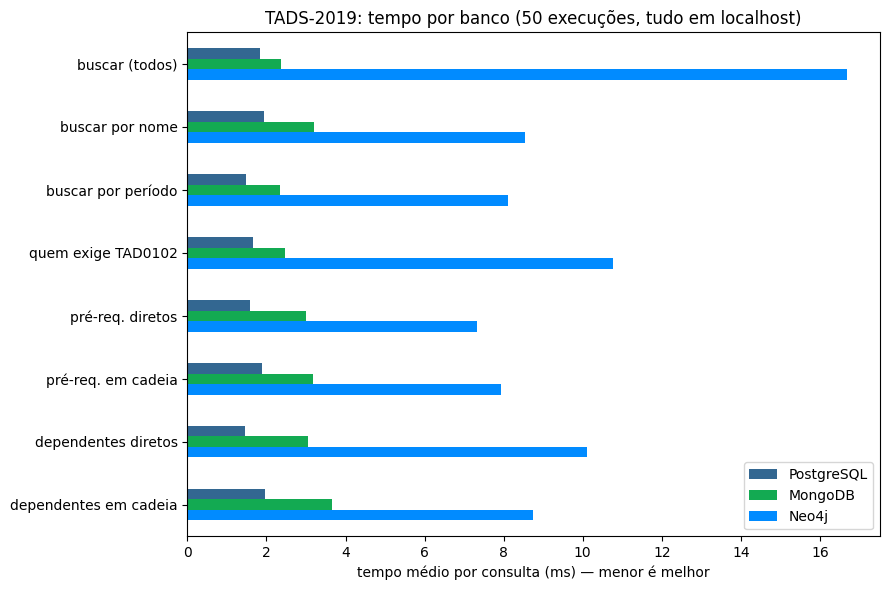

In [14]:
ax = tabela.plot.barh(figsize=(9, 6), color=["#336791", "#13aa52", "#018bff"])
ax.invert_yaxis()
ax.set_xlabel("tempo médio por consulta (ms) — menor é melhor")
ax.set_ylabel("")
ax.set_title(f"TADS-2019: tempo por banco ({N} execuções, tudo em localhost)")
ax.legend(title="")
plt.tight_layout()
plt.show()

A média geral de cada banco, somando as 8 consultas:

In [15]:
print("Média geral por banco (ms):")
tabela.mean().round(2).to_frame("média")

Média geral por banco (ms):


,média
banco,
PostgreSQL,1.73
MongoDB,2.91
Neo4j,9.78


## 5. Leitura dos resultados

**Corretude.** Os três bancos devolveram exatamente a mesma resposta em todas as consultas. Os modelos são diferentes, mas representam a mesma informação sem perdas, inclusive a regra E/OU.

**Tempo.** Na execução salva neste notebook, o PostgreSQL foi o mais rápido, o MongoDB ficou perto e o Neo4j foi o mais lento. Mas é preciso cuidado ao interpretar:

- O volume é **muito pequeno**: 37 componentes e menos de 100 relações. Nesse tamanho, as diferenças são de milissegundos e vêm sobretudo do **custo fixo de cada driver e protocolo**, não da estratégia de consulta.
- Por isso este benchmark **não** mostra como cada banco se comportaria com milhões de registros. Em um grafo muito grande, com cadeias longas, a navegação por relacionamentos tenderia a favorecer o Neo4j.
- Os tempos mudam um pouco a cada execução, mas a ordem entre os bancos tende a se repetir.

**Forma de escrever.** A maior diferença visível entre os modelos é a clareza da consulta de cadeia de pré-requisitos: `WITH RECURSIVE` no SQL, `$graphLookup` no MongoDB e `-[:REQUER*]->` no Cypher.

**Escolha.** Para este sistema, a recomendação é o **PostgreSQL**: dados pequenos e bem estruturados, consultas que são em sua maioria filtros, cadeia de pré-requisitos resolvida pelo `WITH RECURSIVE` e facilidade para cadastrar outros cursos no mesmo esquema. A justificativa completa, incluindo quando Neo4j ou MongoDB seriam melhores, está em [`docs/justificativa.md`](../docs/justificativa.md).